# Doppler-free spectroscopy of the Rb D2 line — data of 2026-11-25

Setup: DFB laser → pump/probe split by a microscope slide → counter-propagating beams through the Rb cell →
probe goes through a ¼-wave plate + polarizing beam-splitter onto two photodiodes (ch1, ch2).
The Moku Laser Lock Box scans the laser current with a 4 Hz triangle (2 Vpp, output 2); we record the photodiode (input 1) and the scan voltage (input 2).

Folders: `nomag/`, `0.5a/`, `1a/` = current through the magnet; `channel1` / `channel2` = only that photodiode connected, `bothdiodes` = both.

**Contents**
1. Constants and line list (theory: transitions, crossovers, relative strengths, separation table, stick sketch)
2. Loading the data + why the baseline is skewed + flattening (→ corrected CSVs)
3. Frequency calibration
4. Doppler-free spectrum (no magnet)
5. Line fits (Gaussian / Lorentzian / Voigt) and lifetime
6. Magnet runs (0.5 A, 1 A)

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import medfilt, find_peaks
from scipy.ndimage import gaussian_filter1d
from scipy.optimize import curve_fit
from scipy.special import voigt_profile

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = ROOT / "data" / "20261125"
PROC = DATA / "processed"; PROC.mkdir(exist_ok=True)
FIG = ROOT / "figures" / "20261125"; FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.figsize": (10, 4.5), "figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})

def save(fig, name):
    fig.tight_layout()
    fig.savefig(FIG / f"{name}.png", dpi=150)
    plt.show()

## 1. Theory: line positions, crossovers, strengths

Hyperfine energies from Steck (Rb85 / Rb87 D-line data). All numbers in MHz.
The transition frequency for ground level F → excited level F' is
$\nu = \nu_{\rm iso} + E(F') - E(F)$ (a *higher* ground level means a *lower* transition frequency).
Selection rule: $\Delta F = 0,\pm1$.
Zero of the frequency axis = ⁸⁵Rb F=3 → F'=4 (strongest closed transition).

In [2]:
# Steck hyperfine data (MHz)
E_GND = {85: {3: +1264.8885, 2: -1770.8439}, 87: {2: +2563.0060, 1: -4271.6770}}               # 5S1/2
E_EXC = {85: {4: +100.205, 3: -20.435, 2: -83.835, 1: -113.208},                                # 5P3/2
         87: {3: +193.7407, 2: -72.9112, 1: -229.8518, 0: -302.0738}}
ISO = {85: 0.0, 87: +78.095}                                                                    # 87-85 isotope shift

# relative strengths S_FF' (Steck, D2 line), keyed by (isotope, F, F')
STRENGTH = {(85, 3, 4): 9/14, (85, 3, 3): 5/18, (85, 3, 2): 5/63,
            (85, 2, 3): 14/45, (85, 2, 2): 7/18, (85, 2, 1): 3/10,
            (87, 2, 3): 7/10, (87, 2, 2): 1/4, (87, 2, 1): 1/20,
            (87, 1, 2): 5/12, (87, 1, 1): 5/12, (87, 1, 0): 1/6}

REF = ISO[85] + E_EXC[85][4] - E_GND[85][3]                    # 85Rb F=3->F'=4, absolute offset (MHz)

TRANS = []
for iso in (85, 87):
    for F in E_GND[iso]:
        for Fp in E_EXC[iso]:
            if abs(F - Fp) <= 1:
                TRANS.append(dict(iso=iso, F=F, Fp=Fp, nu=ISO[iso] + E_EXC[iso][Fp] - E_GND[iso][F] - REF, S=STRENGTH[iso, F, Fp]))
# crossovers sit midway between two excited levels sharing a ground level
CROSS = []
for iso in (85, 87):
    for F in E_GND[iso]:
        tt = sorted([t for t in TRANS if t["iso"] == iso and t["F"] == F], key=lambda t: t["nu"])
        for a in range(len(tt)):
            for b in range(a+1, len(tt)):
                CROSS.append(dict(iso=iso, F=F, Fp=(tt[a]["Fp"], tt[b]["Fp"]), nu=(tt[a]["nu"] + tt[b]["nu"]) / 2))

def centroid(iso, F):
    tt = [t for t in TRANS if t["iso"] == iso and t["F"] == F]
    return sum(t["nu"] * t["S"] for t in tt) / sum(t["S"] for t in tt)

LINES = [(87, 2), (85, 3), (85, 2), (87, 1)]                    # the four Doppler-broadened lines (increasing frequency)
LINES = sorted(LINES, key=lambda l: centroid(*l))
lname = lambda l: f"$^{{{l[0]}}}$Rb F={l[1]}"
print("Doppler-line centroids (MHz, rel. to 85Rb F=3->4):", {f"{i}Rb F={F}": round(centroid(i, F), 1) for i, F in LINES})

Doppler-line centroids (MHz, rel. to 85Rb F=3->4): {'87Rb F=2': -1214.3, '85Rb F=3': -48.1, '85Rb F=2': 2862.6, '87Rb F=1': 5338.0}


In [3]:
rows = [(t["nu"], f"{t['iso']}Rb F={t['F']}->F'={t['Fp']}", t["S"]) for t in TRANS] + \
       [(c["nu"], f"{c['iso']}Rb F={c['F']} CO F'={c['Fp'][0]}/{c['Fp'][1]}", np.nan) for c in CROSS]
rows.sort()
print(f"{'label':28s} {'nu (MHz)':>10s} {'S_FF':>7s}")
for nu, lab, S in rows:
    print(f"{lab:28s} {nu:10.1f} {'' if np.isnan(S) else f'{S:7.3f}'}")

# separations within each Doppler-broadened line (what the Doppler-free spectrum can resolve)
print()
for iso, F in LINES:
    grp = sorted([(t["nu"], f"F'={t['Fp']}") for t in TRANS if t["iso"] == iso and t["F"] == F] +
                 [(c["nu"], f"CO{c['Fp'][0]}/{c['Fp'][1]}") for c in CROSS if c["iso"] == iso and c["F"] == F])
    print(f"{iso}Rb F={F}: " + "  ".join(f"{lab}@{nu:+.1f}" for nu, lab in grp))
    print("   neighbour spacing (MHz): " + ", ".join(f"{b[0]-a[0]:.1f}" for a, b in zip(grp, grp[1:])))

label                          nu (MHz)    S_FF
87Rb F=2->F'=1                  -1550.1   0.050
87Rb F=2 CO F'=1/2              -1471.6 
87Rb F=2->F'=2                  -1393.1   0.250
87Rb F=2 CO F'=1/3              -1338.3 
87Rb F=2 CO F'=2/3              -1259.8 
87Rb F=2->F'=3                  -1126.5   0.700
85Rb F=3->F'=2                   -184.0   0.079
85Rb F=3 CO F'=2/3               -152.3 
85Rb F=3->F'=3                   -120.6   0.278
85Rb F=3 CO F'=2/4                -92.0 
85Rb F=3 CO F'=3/4                -60.3 
85Rb F=3->F'=4                      0.0   0.643
85Rb F=2->F'=1                   2822.3   0.300
85Rb F=2 CO F'=1/2               2837.0 
85Rb F=2->F'=2                   2851.7   0.389
85Rb F=2 CO F'=1/3               2868.7 
85Rb F=2 CO F'=2/3               2883.4 
85Rb F=2->F'=3                   2915.1   0.311
87Rb F=1->F'=0                   5212.4   0.167
87Rb F=1 CO F'=0/1               5248.5 
87Rb F=1->F'=1                   5284.6   0.417
87Rb F=1 CO F'

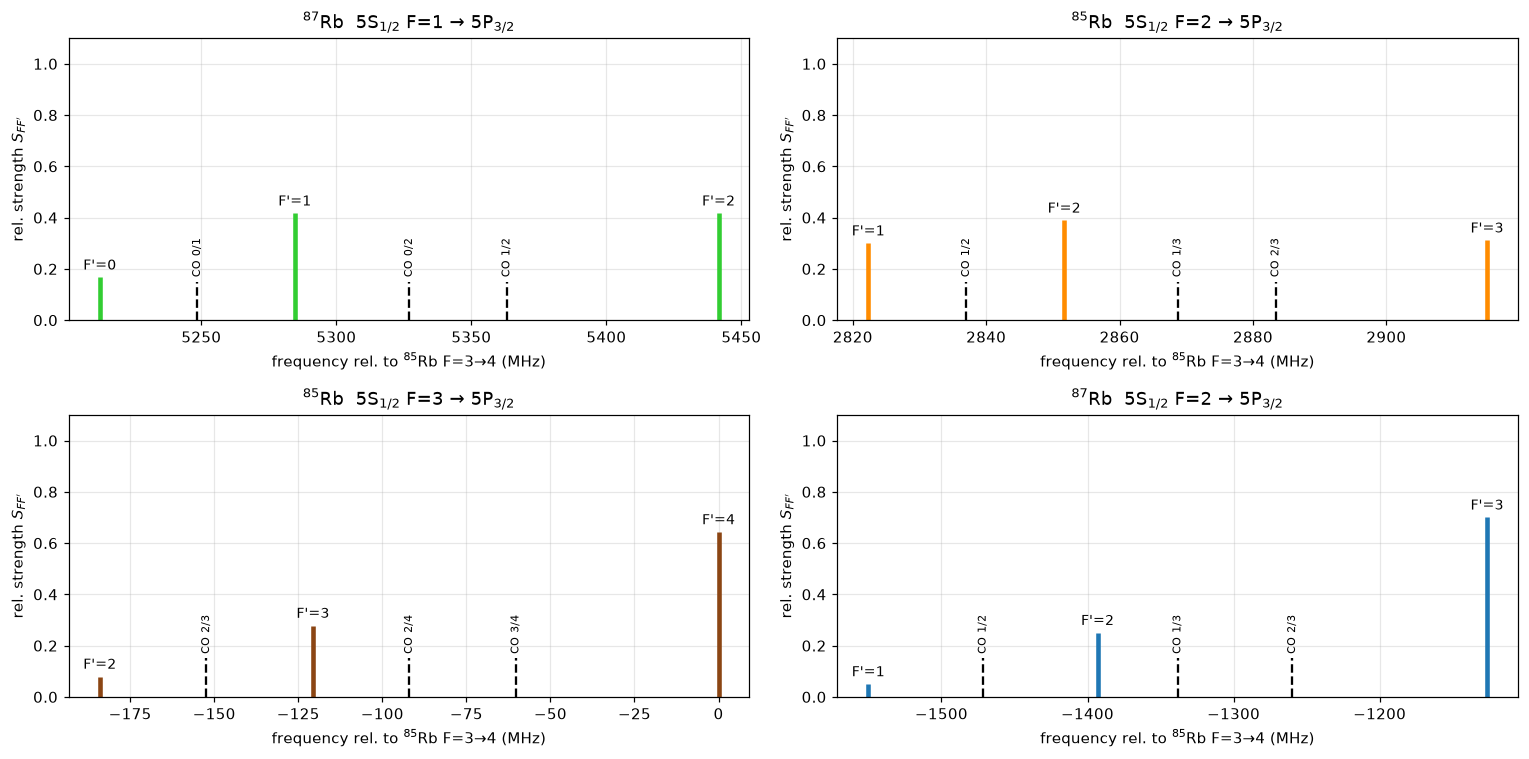

In [4]:
COL = {(85, 3): "saddlebrown", (85, 2): "darkorange", (87, 2): "tab:blue", (87, 1): "limegreen"}
fig, ax = plt.subplots(2, 2, figsize=(14, 7))
for a, (iso, F) in zip(ax.ravel(), reversed(LINES)):
    for t in [t for t in TRANS if t["iso"] == iso and t["F"] == F]:
        a.vlines(t["nu"], 0, t["S"], color=COL[(iso, F)], lw=3)
        a.annotate(f"F'={t['Fp']}", (t["nu"], t["S"]), ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")
    for c in [c for c in CROSS if c["iso"] == iso and c["F"] == F]:
        a.vlines(c["nu"], 0, 0.15, color="k", lw=1.5, ls="--")
        a.annotate(f"CO {c['Fp'][0]}/{c['Fp'][1]}", (c["nu"], 0.15), ha="center", va="bottom", fontsize=7, rotation=90, xytext=(0, 3), textcoords="offset points")
    a.set_ylim(0, 1.1); a.set_title(f"$^{{{iso}}}$Rb  5S$_{{1/2}}$ F={F} → 5P$_{{3/2}}$"); a.set_xlabel("frequency rel. to $^{85}$Rb F=3→4 (MHz)"); a.set_ylabel("rel. strength $S_{FF'}$")
save(fig, "00_sketch_transitions")

## 2. Loading, baseline and flattening

**Why is the baseline skewed?** The DFB laser is tuned by modulating its injection current. The current ramp does not only change the wavelength,
it also changes the output power (P ∝ I − I_th), so the light on the photodiode rises linearly while we scan; the Rb absorption dips sit on top of that ramp.
The fix is to divide by a baseline fitted to the line-free parts of the trace (dividing, not subtracting, because absorption is multiplicative: $I = I_0(\nu)\,e^{-\alpha(\nu)}$), giving $\alpha = -\ln(I/I_0)$.

Data format of the `*_HighRes.csv` files: time (s), **input 1 = photodiode**, input 2 = scan voltage.
The ch2 photodiode signal is negative (inverted polarity), so it is multiplied by −1.

In [5]:
def hr_file(folder):
    return max((DATA / folder).glob("*_HighRes.csv"), key=lambda f: f.stat().st_size)

def load(folder):
    t, sig, scan = np.loadtxt(hr_file(folder), delimiter=",", comments="%").T
    if np.median(sig) < 0:                       # photodiode 2 is wired with inverted polarity
        sig = -sig
    return t, sig, scan

def despike(sig, k=9):
    return medfilt(sig, k)

def fit_baseline(x, y, deg=2, nsig=4, iters=15, grow=0.02, edge_only=None):
    good = (y < 4.95)                                           # the photodiode clips at 5 V
    if edge_only is not None:
        good &= edge_only
    use = good.copy()
    for _ in range(iters):
        c = np.polyfit(x[use], y[use], deg); b = np.polyval(c, x)
        r = y - b; sig = 1.4826 * np.median(np.abs(r[use]))
        bad = good & (np.abs(r) > nsig * max(sig, 1e-4))
        if grow:
            xb = x[bad]
            if xb.size:
                lo, hi = np.searchsorted(np.sort(xb), x - grow), np.searchsorted(np.sort(xb), x + grow)
                near = hi > lo
                bad = bad | (good & near)
        new = good & ~bad
        if new.sum() < 50 or (new == use).all(): break
        use = new
    return np.polyval(np.polyfit(x[use], y[use], deg), x), use

def flatten(folder, **kw):
    t, sig, scan = load(folder)
    clean = despike(sig)
    base, used = fit_baseline(scan, clean, **kw)
    ok = clean < 4.95
    absorb = np.where(ok, -np.log(np.clip(clean, 1e-3, None) / base), np.nan)
    return dict(t=t, scan=scan, raw=sig, clean=clean, base=base, used=used, A=absorb)

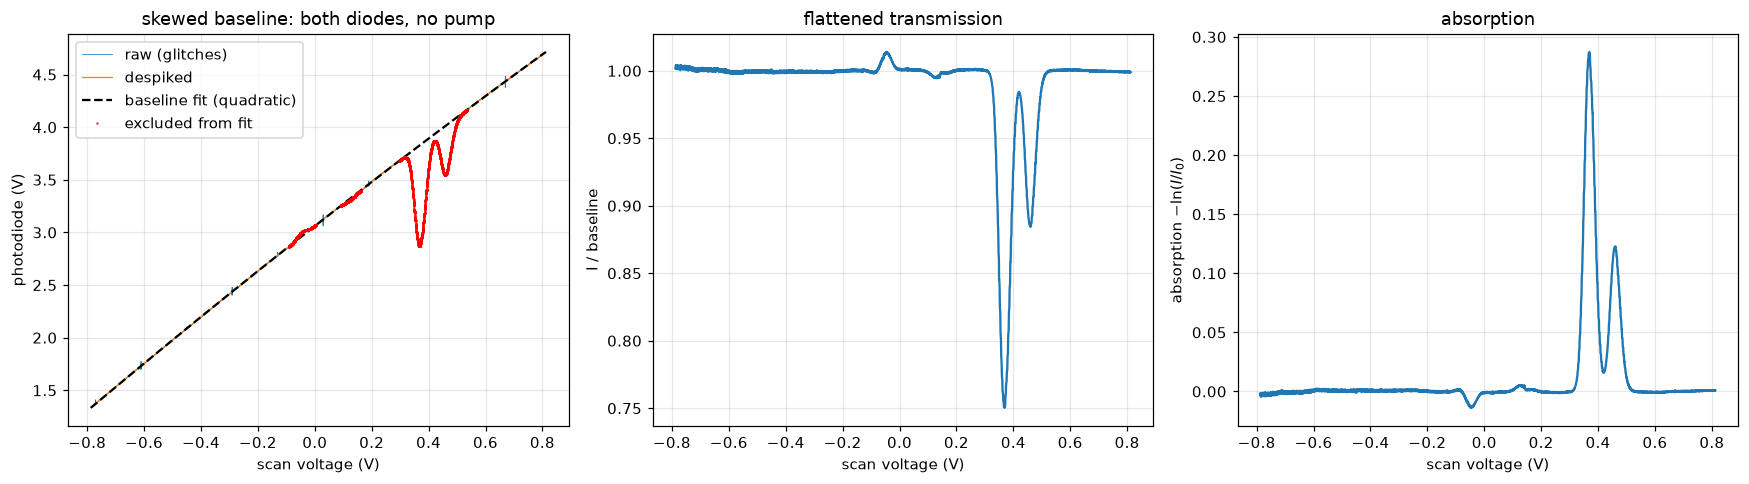

baseline rms of line-free region: 9.6e-04


In [6]:
NOMAG = {  # name: (with pump folder, without pump folder)
    "both": ("nomag/bothdiodes/withpumpbeam", "nomag/bothdiodes/withoutpumpbeam"),
    "ch1":  ("nomag/channel1/withpump",       "nomag/channel1/withoutpump"),
    "ch2":  ("nomag/channel2/withpump",       "nomag/channel2/withoutpump"),
}
R = {}
for name, (pump, nopump) in NOMAG.items():
    R[name, "pump"] = flatten(pump); R[name, "nopump"] = flatten(nopump)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
r = R["both", "nopump"]
ax[0].plot(r["scan"], r["raw"], lw=.5, label="raw (glitches)"); ax[0].plot(r["scan"], r["clean"], lw=.8, label="despiked")
ax[0].plot(r["scan"], r["base"], "k--", label="baseline fit (quadratic)"); ax[0].plot(r["scan"][~r["used"]], r["clean"][~r["used"]], "r.", ms=1, label="excluded from fit")
ax[0].set(xlabel="scan voltage (V)", ylabel="photodiode (V)", title="skewed baseline: both diodes, no pump"); ax[0].legend()
ax[1].plot(r["scan"], r["clean"] / r["base"]); ax[1].set(xlabel="scan voltage (V)", ylabel="I / baseline", title="flattened transmission")
ax[2].plot(r["scan"], r["A"]); ax[2].set(xlabel="scan voltage (V)", ylabel=r"absorption $-\ln(I/I_0)$", title="absorption")
save(fig, "01_baseline")
print("baseline rms of line-free region: %.1e" % r["A"][r["used"] & np.isfinite(r["A"])].std())

## 3. Frequency calibration

Each scan is recorded against the scan voltage, so we need volts → MHz. The two Doppler-broadened dips in the window are
⁸⁵Rb F=3 (deep) and ⁸⁷Rb F=2 (shallower); their separation is known from the line table above, which gives the slope.
Each run is calibrated on its own (laser drift shifts the position by ≈0.01 V between runs).
The laser frequency *decreases* with increasing scan voltage here, so the sign is part of the fit.

In [7]:
NU_85F3, NU_87F2 = centroid(85, 3), centroid(87, 2)
DNU = NU_85F3 - NU_87F2                          # MHz, > 0 : 85F3 sits at higher frequency

def gauss(x, a, c, w): return a * np.exp(-0.5 * ((x - c) / w) ** 2)
def two_gauss(x, off, a1, c1, w1, a2, c2, w2): return off + gauss(x, a1, c1, w1) + gauss(x, a2, c2, w2)

def calibrate(r):
    x = r["scan"]; ok = np.isfinite(r["A"])
    ys = gaussian_filter1d(np.nan_to_num(r["A"]), 120)          # ~0.7 ms: keeps the Doppler envelope only
    pk, pr = find_peaks(ys, prominence=0.02)
    pk = np.sort(pk[np.argsort(-ys[pk])][:2])                   # two strongest, ordered by increasing scan voltage
    p0 = [0, ys[pk[0]], x[pk[0]], 0.03, ys[pk[1]], x[pk[1]], 0.03]
    sel = (x > x[pk[0]] - 0.2) & (x < x[pk[1]] + 0.2) & ok
    p, _ = curve_fit(two_gauss, x[sel], ys[sel], p0=p0)
    return dict(c85=p[2], c87=p[5], k=DNU / (p[5] - p[2]), w85=abs(p[3]), w87=abs(p[6]), a85=p[1], a87=p[4])

for name in NOMAG:
    r = R[name, "nopump"]; r["cal"] = calibrate(r)
    c = r["cal"]
    print(f"{name:5s} no pump  85F3 @ {c['c85']:.4f} V  87F2 @ {c['c87']:.4f} V   k = {c['k']/1e3:.2f} GHz/V   "
          f"Doppler FWHM: 85F3 {2.355*c['w85']*c['k']:.0f} MHz, 87F2 {2.355*c['w87']*c['k']:.0f} MHz   depth ratio 85F3/87F2 = {c['a85']/c['a87']:.2f}")
K_MEAN = np.mean([R[n, "nopump"]["cal"]["k"] for n in NOMAG])             # MHz/V
K_SPREAD = np.std([R[n, "nopump"]["cal"]["k"] for n in NOMAG])
print(f"\ncalibration slope: {K_MEAN/1e3:.2f} GHz/V (spread between runs {K_SPREAD/1e3:.2f})")

# pump runs reuse the no-pump calibration (their envelope is distorted by the pump)
for name in NOMAG:
    c = R[name, "nopump"]["cal"]
    for mode in ("nopump", "pump"):
        r = R[name, mode]
        r["nu"] = NU_85F3 + K_MEAN * (c["c85"] - r["scan"])            # MHz, 0 = 85Rb F=3->F'=4

for (name, mode), r in R.items():
    out = np.column_stack([r["t"], r["scan"], r["nu"], r["raw"], r["clean"], r["base"], r["clean"] / r["base"], r["A"]])
    np.savetxt(PROC / f"nomag_{name}_{mode}.csv", out, delimiter=",", fmt="%.6g",
               header="t_s,scan_V,freq_MHz_rel_85F3to4,photodiode_raw_V,photodiode_despiked_V,baseline_V,transmission,absorption", comments="")
print(sorted(p.name for p in PROC.glob("*.csv")))

both  no pump  85F3 @ 0.3696 V  87F2 @ 0.4599 V   k = 12.91 GHz/V   Doppler FWHM: 85F3 655 MHz, 87F2 661 MHz   depth ratio 85F3/87F2 = 2.40
ch1   no pump  85F3 @ 0.3684 V  87F2 @ 0.4584 V   k = 12.95 GHz/V   Doppler FWHM: 85F3 680 MHz, 87F2 684 MHz   depth ratio 85F3/87F2 = 2.41
ch2   no pump  85F3 @ 0.3678 V  87F2 @ 0.4575 V   k = 13.01 GHz/V   Doppler FWHM: 85F3 686 MHz, 87F2 711 MHz   depth ratio 85F3/87F2 = 2.36

calibration slope: 12.96 GHz/V (spread between runs 0.04)
['0.5a_both_nopump.csv', '0.5a_both_pump.csv', '0.5a_ch1_nopump.csv', '0.5a_ch1_pump.csv', '0.5a_ch2_nopump.csv', '0.5a_ch2_pump.csv', '1a_both_nopump.csv', '1a_both_pump.csv', '1a_ch1_nopump.csv', '1a_ch1_pump.csv', '1a_ch2_nopump.csv', '1a_ch2_pump.csv', 'nomag_both_nopump.csv', 'nomag_both_pump.csv', 'nomag_ch1_nopump.csv', 'nomag_ch1_pump.csv', 'nomag_ch2_nopump.csv', 'nomag_ch2_pump.csv']


## 4. Doppler-free spectrum (no magnet)

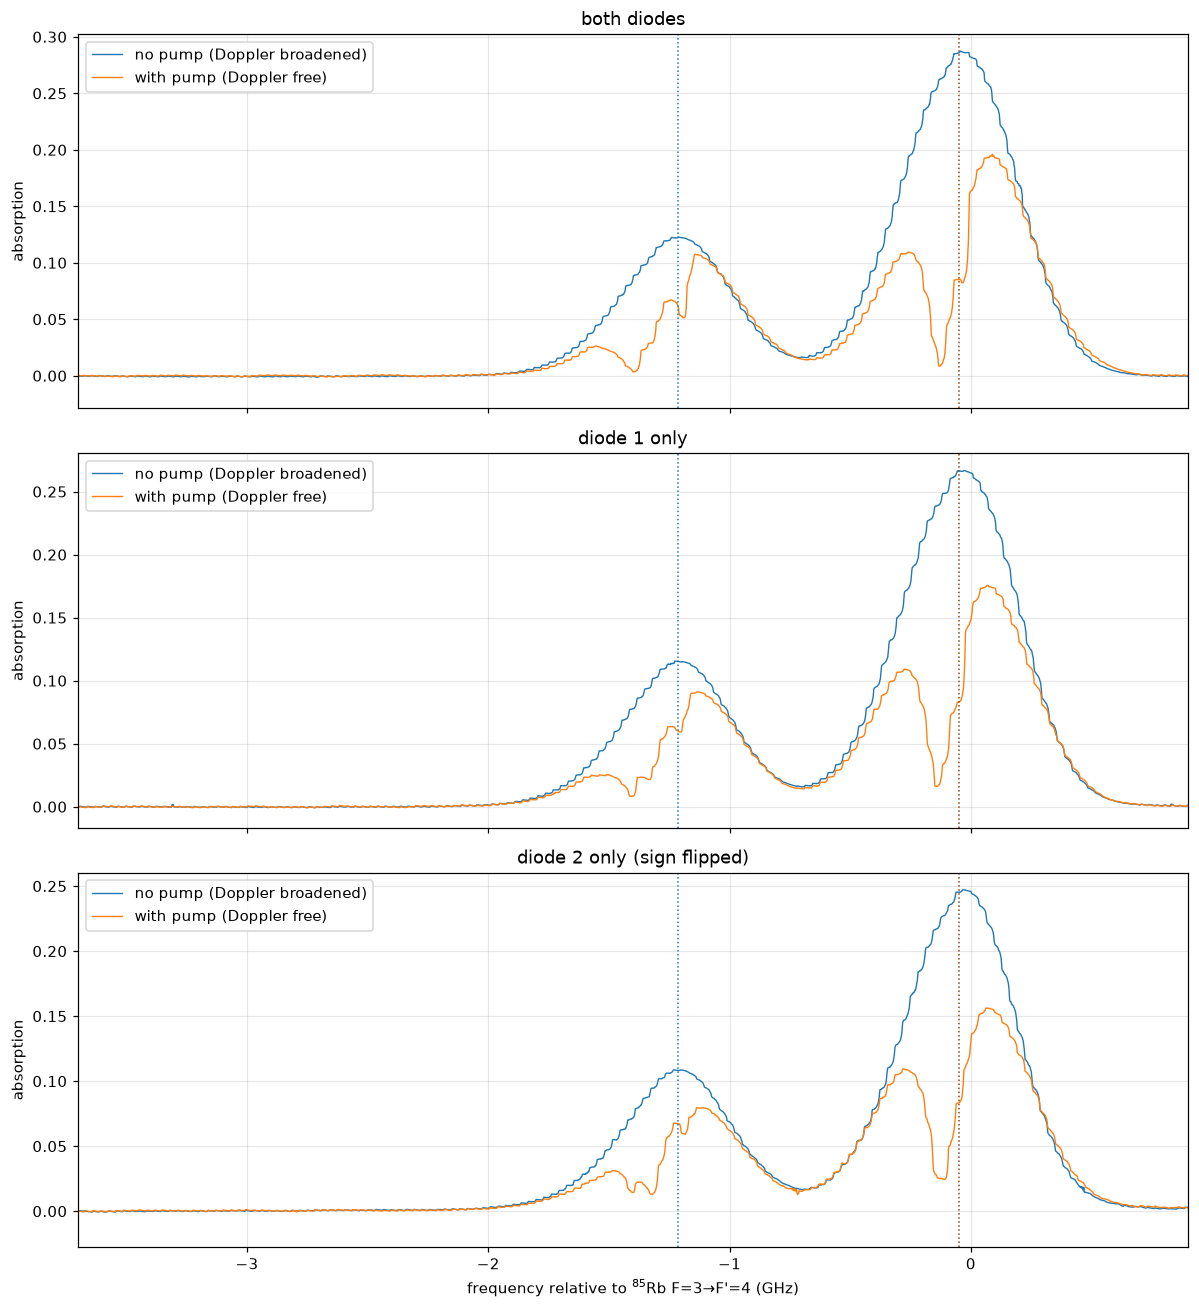

In [8]:
fig, ax = plt.subplots(3, 1, figsize=(11, 12), sharex=True)
for a, name in zip(ax, NOMAG):
    for mode, lab in (("nopump", "no pump (Doppler broadened)"), ("pump", "with pump (Doppler free)")):
        r = R[name, mode]; a.plot(r["nu"] / 1e3, r["A"], lw=.9, label=lab)
    a.set_ylabel("absorption"); a.set_title({"both": "both diodes", "ch1": "diode 1 only", "ch2": "diode 2 only (sign flipped)"}[name]); a.legend()
    for iso, F in LINES: a.axvline(centroid(iso, F) / 1e3, color=COL[iso, F], ls=":", lw=1)
ax[-1].set_xlabel("frequency relative to $^{85}$Rb F=3→F'=4 (GHz)"); ax[-1].set_xlim(-3.7, 0.9)
save(fig, "02_doppler_free_overview")

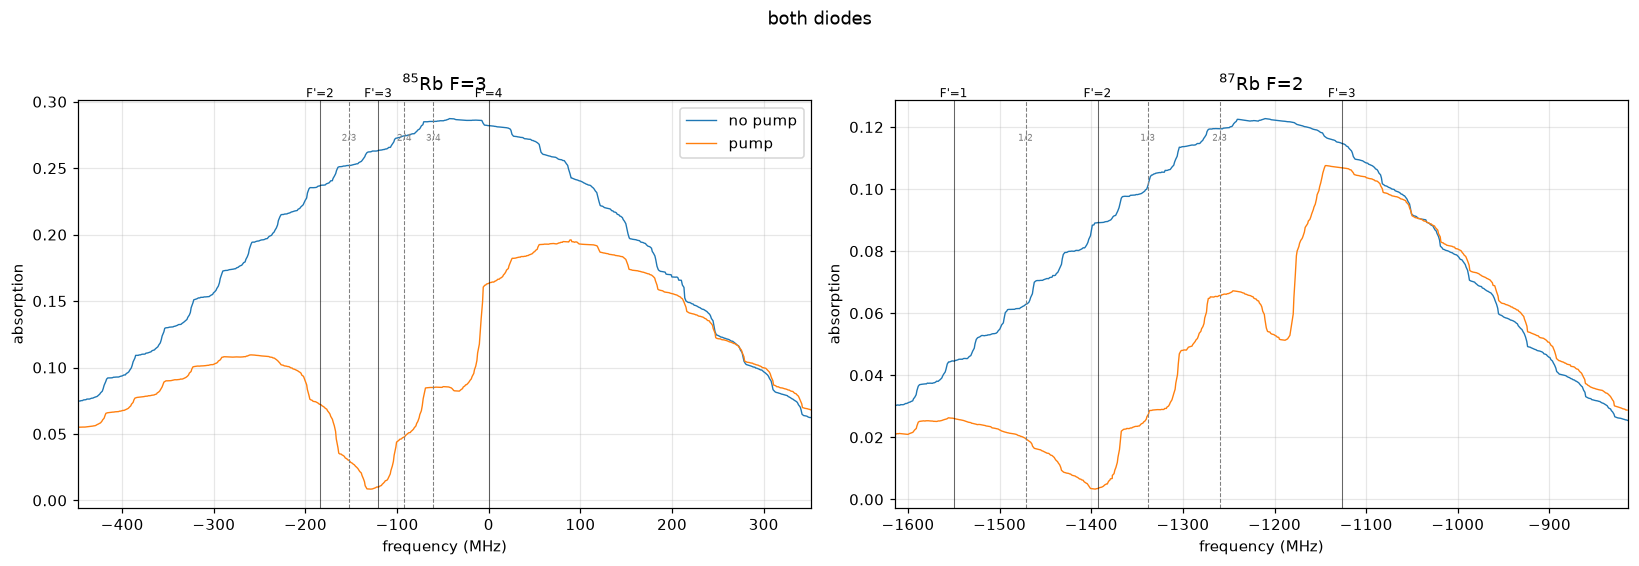

In [9]:
def zoom(name, iso, F, half=400, ax=None):
    ax = ax or plt.gca()
    for mode, lab in (("nopump", "no pump"), ("pump", "pump")):
        r = R[name, mode]; sel = np.abs(r["nu"] - centroid(iso, F)) < half
        ax.plot(r["nu"][sel], r["A"][sel], lw=.9, label=lab)
    for t in [t for t in TRANS if t["iso"] == iso and t["F"] == F]:
        ax.axvline(t["nu"], color="k", lw=.7, alpha=.6); ax.annotate(f"F'={t['Fp']}", (t["nu"], 1), xycoords=("data", "axes fraction"), fontsize=8, ha="center", va="bottom")
    for c in [c for c in CROSS if c["iso"] == iso and c["F"] == F]:
        ax.axvline(c["nu"], color="gray", lw=.7, ls="--"); ax.annotate(f"{c['Fp'][0]}/{c['Fp'][1]}", (c["nu"], 0.9), xycoords=("data", "axes fraction"), fontsize=6, ha="center", color="gray")
    ax.set(xlabel="frequency (MHz)", ylabel="absorption", title=lname((iso, F)), xlim=(centroid(iso, F) - half, centroid(iso, F) + half))

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
zoom("both", 85, 3, ax=ax[0]); zoom("both", 87, 2, ax=ax[1]); ax[0].legend()
fig.suptitle("both diodes", y=1.02)
save(fig, "03_zoom_lines")

## 5. Line fits and lifetime

The saturated-absorption features appear as narrow dips in the absorption (= narrow transparency windows) on top of the Doppler profile.
For each dip we fit a local model (quadratic background + one line) with three line shapes and compare χ²:
Gaussian, Lorentzian and Voigt (Gaussian width tied to the instrumental part, see below).
For a Lorentzian, FWHM $\Gamma = 1/(2\pi\tau)$ → $\tau = 1/(2\pi\,\Delta\nu_{\rm FWHM})$.

Caveats that matter for the lifetime:
* The D2 line only involves the **5²P₃/₂** state. The 5²P₁/₂ lifetime needs the D1 line (795 nm), which was not measured.
* The measured width is not the natural width (6.07 MHz, τ = 26.2 ns): power broadening, transit-time broadening, the pump/probe angle (residual Doppler), laser linewidth, the 100 kHz low-pass and unresolved neighbouring components all add to it. The result is therefore a **lower bound on τ**.

In [10]:
def lor(x, a, c, w):  return a / (1 + ((x - c) / (w / 2)) ** 2)                 # w = FWHM
def gau(x, a, c, w):  return a * np.exp(-4 * np.log(2) * ((x - c) / w) ** 2)    # w = FWHM
def voi(x, a, c, w, f):                                                         # w = total FWHM, f = Lorentzian fraction (0..1)
    wl, wg = f * w, (1 - f) * w                                                 # crude split: Lorentz/Gauss FWHM sum to w
    s, g = max(wg / 2.3548, 1e-3), wl / 2
    p = voigt_profile(x - c, s, max(g, 1e-3)); return a * p / voigt_profile(0, s, max(g, 1e-3))

def local_fit(nu, A, c0, shape, half=100):
    sel = np.isfinite(A) & (np.abs(nu - c0) < half); x, y = nu[sel], A[sel]
    bg = lambda x, b0, b1, b2: b0 + b1 * (x - c0) + b2 * (x - c0) ** 2
    amp0 = np.median(y) - y.min()
    if shape == "lor": f = lambda x, b0, b1, b2, a, c, w: bg(x, b0, b1, b2) - lor(x, a, c, w); p0 = [np.median(y), 0, 0, amp0, c0, 25]; lo = [-5, -1, -1, 0, c0 - 20, 3]; hi = [5, 1, 1, 5, c0 + 20, 200]
    if shape == "gau": f = lambda x, b0, b1, b2, a, c, w: bg(x, b0, b1, b2) - gau(x, a, c, w); p0 = [np.median(y), 0, 0, amp0, c0, 25]; lo = [-5, -1, -1, 0, c0 - 20, 3]; hi = [5, 1, 1, 5, c0 + 20, 200]
    if shape == "voi": f = lambda x, b0, b1, b2, a, c, w, fr: bg(x, b0, b1, b2) - voi(x, a, c, w, fr); p0 = [np.median(y), 0, 0, amp0, c0, 25, .5]; lo = [-5, -1, -1, 0, c0 - 20, 3, 0]; hi = [5, 1, 1, 5, c0 + 20, 200, 1]
    p, cov = curve_fit(f, x, y, p0=p0, bounds=(lo, hi))
    res = y - f(x, *p); return p, np.sqrt(np.diag(cov)), np.sqrt(np.mean(res ** 2)), x, y, f

both 85 3 dips at (MHz): -125 (nearest 85Rb F=3->F'=3, off -4)
both 87 2 dips at (MHz): -1395 (nearest 87Rb F=2->F'=2, off -2), -1195 (nearest 87Rb F=2 CO F'=2/3, off +64)
ch1 85 3 dips at (MHz): -137 (nearest 85Rb F=3 CO F'=2/3, off +15)
ch1 87 2 dips at (MHz): -1406 (nearest 87Rb F=2->F'=2, off -13)


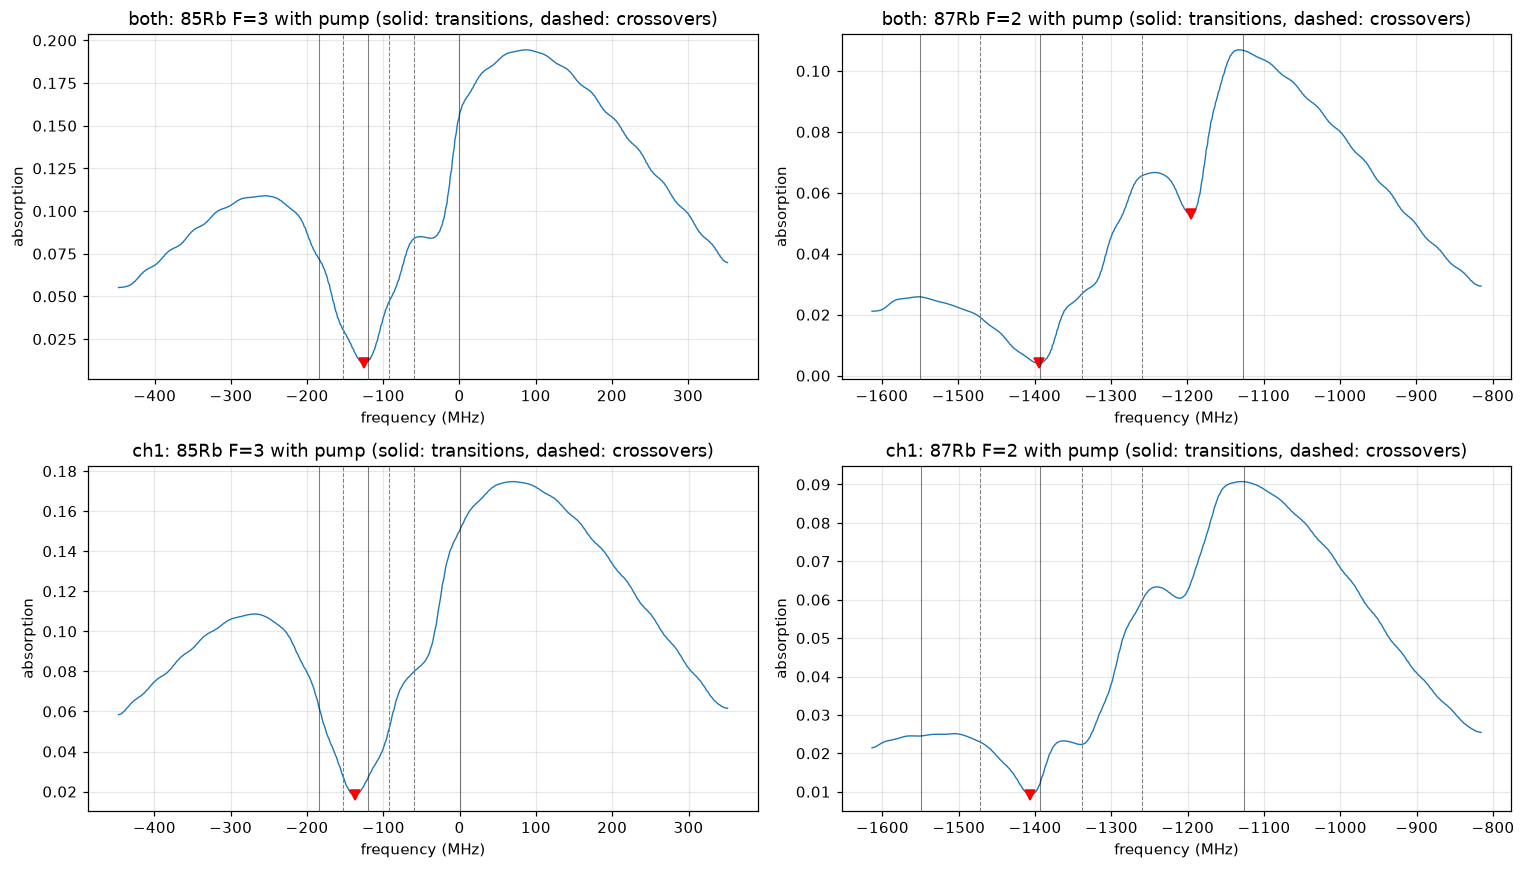

In [11]:
def narrow_peaks(r, iso, F, half=400, prom=0.01):
    sel = np.isfinite(r["A"]) & (np.abs(r["nu"] - centroid(iso, F)) < half)
    nu, A = r["nu"][sel], r["A"][sel]
    order = np.argsort(nu); nu, A = nu[order], A[order]
    As = gaussian_filter1d(A, 6)                                                # ~35 us, removes the ADC staircase
    pk, _ = find_peaks(-As, prominence=prom, width=3)
    return nu, As, pk

def nearest(nu0):
    nu_, lab_, _ = min(rows, key=lambda r_: abs(r_[0] - nu0)); return lab_, nu0 - nu_

CHANNELS = ("both", "ch1")                       # ch2 with pump behaves differently (see overview) and is not fitted
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
FEATS = {}
for i, ch in enumerate(CHANNELS):
    for j, (iso, F) in enumerate([(85, 3), (87, 2)]):
        a = ax[i, j]; nu, As, pk = narrow_peaks(R[ch, "pump"], iso, F)
        a.plot(nu, As, lw=.9); a.plot(nu[pk], As[pk], "rv")
        for t in [t for t in TRANS if t["iso"] == iso and t["F"] == F]: a.axvline(t["nu"], color="k", lw=.7, alpha=.5)
        for c in [c for c in CROSS if c["iso"] == iso and c["F"] == F]: a.axvline(c["nu"], color="gray", lw=.7, ls="--")
        a.set(title=f"{ch}: {iso}Rb F={F} with pump (solid: transitions, dashed: crossovers)", xlabel="frequency (MHz)", ylabel="absorption")
        FEATS[ch, iso, F] = nu[pk]
        print(ch, iso, F, "dips at (MHz):", ", ".join(f"{x:.0f} (nearest {nearest(x)[0]}, off {nearest(x)[1]:+.0f})" for x in nu[pk]))
save(fig, "04_narrow_features")

In [12]:
FITS = []
print(f"{'data':5s} {'line':10s} {'centre (MHz)':>12s} | {'rms Gauss':>9s} {'rms Lor':>9s} {'rms Voigt':>9s} | FWHM Lor (MHz)  -> tau (ns)")
for (ch, iso, F), peaks in FEATS.items():
    r = R[ch, "pump"]
    for c0 in peaks:
        try:
            out = {s_: local_fit(r["nu"], r["A"], c0, s_) for s_ in ("gau", "lor", "voi")}
        except (RuntimeError, ValueError):
            continue
        pl, el = out["lor"][0], out["lor"][1]
        FITS.append(dict(ch=ch, iso=iso, F=F, c0=c0, fits=out))
        print(f"{ch:5s} {iso}Rb F={F:<3d} {pl[4]:12.1f} | {out['gau'][2]:9.2e} {out['lor'][2]:9.2e} {out['voi'][2]:9.2e} | "
              f"{pl[5]:6.1f} ± {el[5]:4.1f}  -> {1/(2*np.pi*pl[5]*1e6)*1e9:5.2f} ns   (Voigt FWHM {out['voi'][0][5]:.1f}, Lorentz fraction {out['voi'][0][6]:.2f})")

data  line       centre (MHz) | rms Gauss   rms Lor rms Voigt | FWHM Lor (MHz)  -> tau (ns)
both  85Rb F=3         -130.1 |  4.46e-03  4.44e-03  4.44e-03 |  147.6 ± 12.0  ->  1.08 ns   (Voigt FWHM 147.6, Lorentz fraction 1.00)
both  87Rb F=2        -1394.8 |  2.39e-03  2.47e-03  2.39e-03 |   44.3 ±  6.8  ->  3.59 ns   (Voigt FWHM 39.8, Lorentz fraction 0.00)
both  87Rb F=2        -1196.0 |  3.15e-03  3.02e-03  3.02e-03 |   62.1 ±  3.4  ->  2.56 ns   (Voigt FWHM 62.1, Lorentz fraction 1.00)
ch1   85Rb F=3         -137.4 |  3.88e-03  3.89e-03  3.89e-03 |  151.8 ± 16.8  ->  1.05 ns   (Voigt FWHM 151.9, Lorentz fraction 1.00)
ch1   87Rb F=2        -1407.2 |  2.02e-03  2.15e-03  2.02e-03 |   33.3 ±  4.3  ->  4.78 ns   (Voigt FWHM 31.4, Lorentz fraction 0.00)


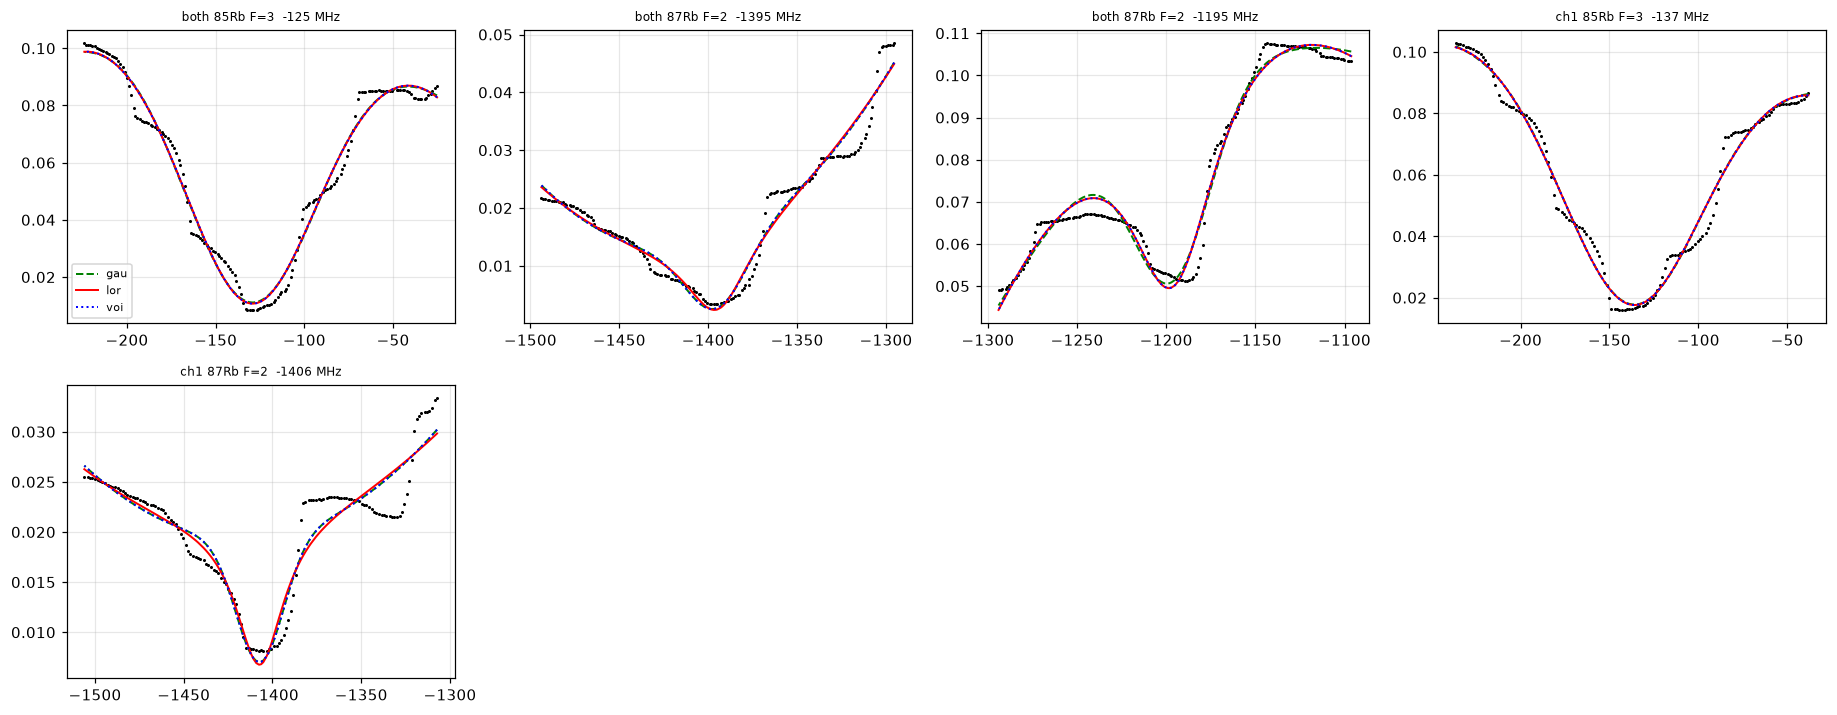

In [13]:
n = len(FITS)
cols = 4; rows_ = int(np.ceil(n / cols)) or 1
fig, ax = plt.subplots(rows_, cols, figsize=(4.2 * cols, 3.3 * rows_), squeeze=False)
for a, fd in zip(ax.ravel(), FITS):
    for s, st in (("gau", "g--"), ("lor", "r-"), ("voi", "b:")):
        p, e, rms, x, y, f = fd["fits"][s]
        if s == "gau": a.plot(x, y, "k.", ms=2)
        a.plot(x, f(x, *p), st, lw=1.3, label=s)
    a.set_title(f"{fd['ch']} {fd['iso']}Rb F={fd['F']}  {fd['c0']:.0f} MHz", fontsize=8)
ax.ravel()[0].legend(fontsize=7)
for a in ax.ravel()[n:]: a.axis("off")
save(fig, "05_fits")

In [14]:
# only the isolated 87Rb F=2->F'=2 dip is used; the 85Rb F=3 dip is a blend of unresolved components
NU_CLEAN = [t["nu"] for t in TRANS if (t["iso"], t["F"], t["Fp"]) == (87, 2, 2)][0]
clean = [fd for fd in FITS if fd["iso"] == 87 and abs(fd["fits"]["lor"][0][4] - NU_CLEAN) < 30]
for shape in ("lor", "gau", "voi"):
    print(f"rms residual {shape}: " + ", ".join(f"{fd['ch']} {fd['fits'][shape][2]:.2e}" for fd in clean))
w = np.array([fd["fits"]["lor"][0][5] for fd in clean]); dw = np.array([fd["fits"]["lor"][1][5] for fd in clean])
wm = np.average(w, weights=1 / dw ** 2); dwm = max(1 / np.sqrt(np.sum(1 / dw ** 2)), w.std())
dwm = np.hypot(dwm, 0.07 * wm)                                                   # + calibration slope uncertainty (~7 %)
tau = 1 / (2 * np.pi * wm * 1e6) * 1e9
print(f"\n87Rb F=2->F'=2 FWHM = {wm:.0f} ± {dwm:.0f} MHz   (natural width 6.07 MHz)")
print(f"tau(5P3/2) >= {tau:.1f} ns  (range {1/(2*np.pi*(wm+dwm)*1e6)*1e9:.1f} - {1/(2*np.pi*(wm-dwm)*1e6)*1e9:.1f} ns)   [literature 26.2 ns]")
print(f"the width is {wm/6.07:.1f}x the natural width -> this is a lower bound on the lifetime, not a measurement of it")

rms residual lor: both 2.47e-03, ch1 2.15e-03
rms residual gau: both 2.39e-03, ch1 2.02e-03
rms residual voi: both 2.39e-03, ch1 2.02e-03

87Rb F=2->F'=2 FWHM = 36 ± 6 MHz   (natural width 6.07 MHz)
tau(5P3/2) >= 4.4 ns  (range 3.7 - 5.2 ns)   [literature 26.2 ns]
the width is 6.0x the natural width -> this is a lower bound on the lifetime, not a measurement of it


## 6. Magnet runs

Current through the magnet = 0.5 A and 1 A. With the quarter-wave plate + PBS the two diodes see the two orthogonal (circular) probe polarizations, so ch1 and ch2 respond differently to the Zeeman-split lines;
`bothdiodes` is the sum. Flattened the same way; the frequency axis uses the mean calibration slope from section 3 and is relative to the deepest dip in each trace.

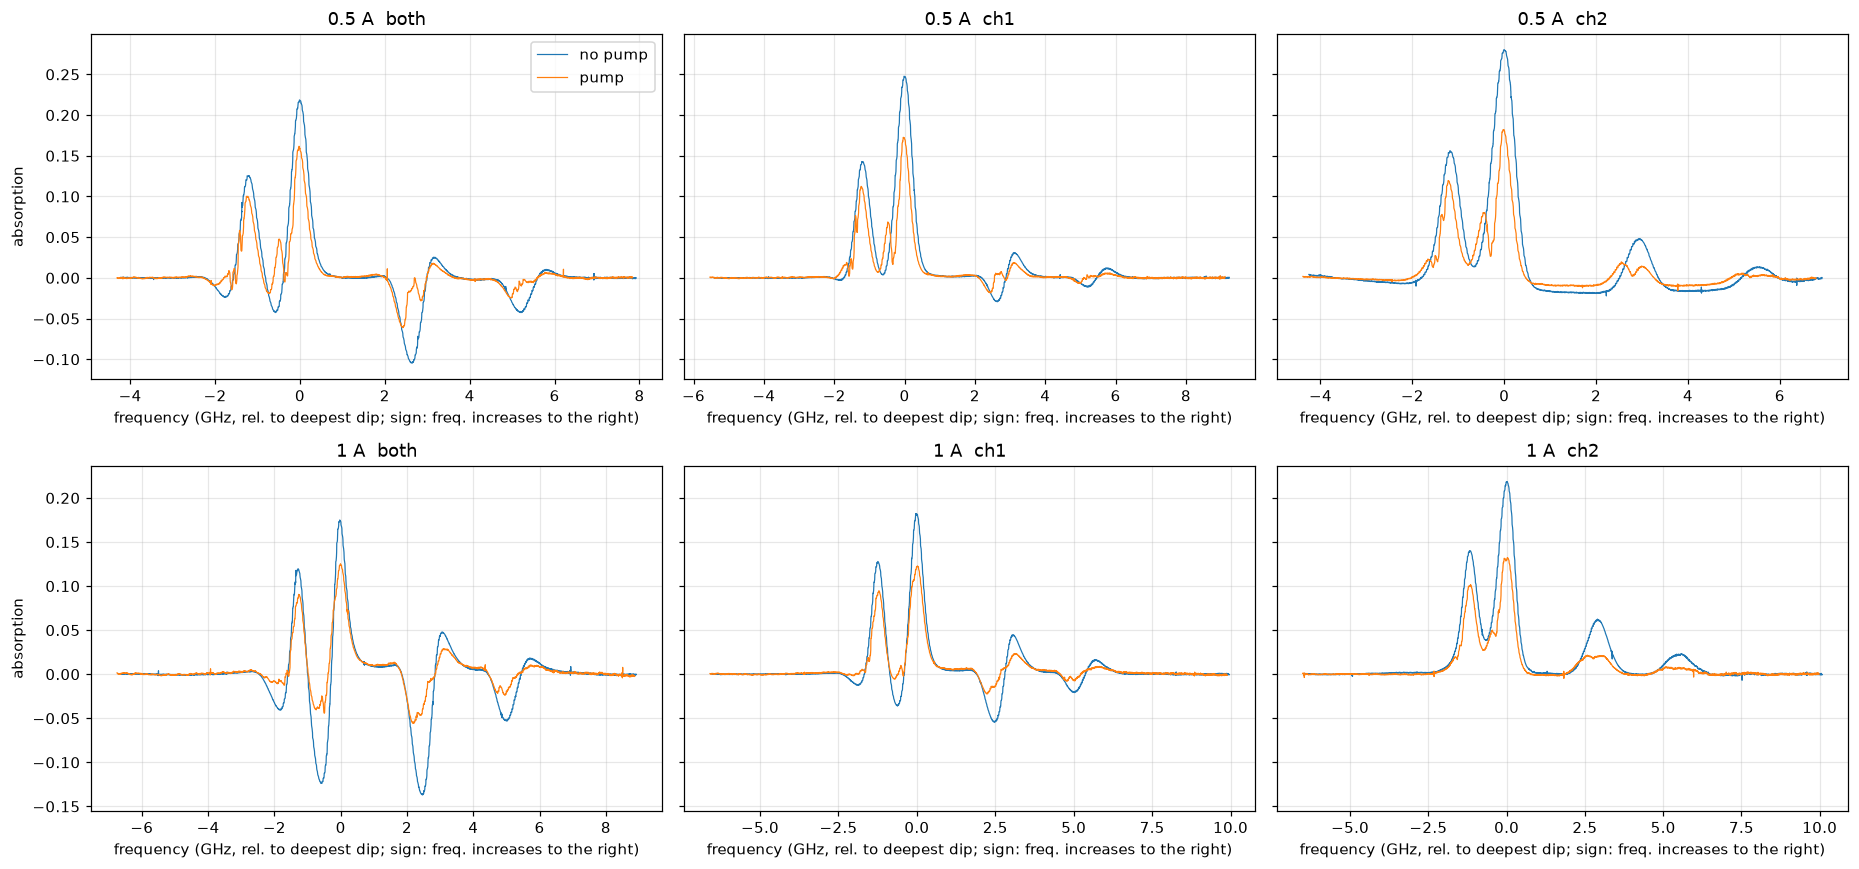

In [15]:
def edge_flatten(folder, frac=.12):
    t, sig, scan = load(folder); clean = despike(sig)
    n = len(scan); lo, hi = np.sort(scan)[[int(frac * n), int((1 - frac) * n)]]
    mask = (scan < lo) | (scan > hi)
    base, used = fit_baseline(scan, clean, deg=2, edge_only=mask, nsig=1e9, iters=1)
    return dict(t=t, scan=scan, raw=sig, clean=clean, base=base, used=used, A=-np.log(np.clip(clean, 1e-3, None) / base))

MAG = {}
for cur in ("0.5a", "1a"):
    both = "bot" if cur == "0.5a" else "bothdiodes"
    for ch, folder in (("both", both), ("ch1", "ch1"), ("ch2", "ch2")):
        for mode, sub in (("pump", "with"), ("nopump", "without")):
            r = MAG[cur, ch, mode] = edge_flatten(f"{cur}/{folder}/{sub}")
            r["nu"] = -K_MEAN * (r["scan"] - r["scan"][np.nanargmax(gaussian_filter1d(r["A"], 120))])
            np.savetxt(PROC / f"{cur}_{ch}_{mode}.csv", np.column_stack([r["t"], r["scan"], r["nu"], r["raw"], r["clean"], r["base"], r["clean"] / r["base"], r["A"]]),
                       delimiter=",", fmt="%.6g", header="t_s,scan_V,freq_MHz_rel_to_deepest_dip,photodiode_raw_V,photodiode_despiked_V,baseline_V,transmission,absorption", comments="")

fig, ax = plt.subplots(2, 3, figsize=(17, 8), sharey="row")
for i, cur in enumerate(("0.5a", "1a")):
    for j, ch in enumerate(("both", "ch1", "ch2")):
        for mode, lab in (("nopump", "no pump"), ("pump", "pump")):
            r = MAG[cur, ch, mode]; ax[i, j].plot(r["nu"] / 1e3, r["A"], lw=.8, label=lab)
        ax[i, j].set_title(f"{cur.replace('a', ' A')}  {ch}"); ax[i, j].set_xlabel("frequency (GHz, rel. to deepest dip; sign: freq. increases to the right)")
ax[0, 0].legend(); ax[0, 0].set_ylabel("absorption"); ax[1, 0].set_ylabel("absorption")
save(fig, "06_magnet")